# Olist Supply Chain Analysis with PySpark

Ad hoc analysis of delivery performance in the [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (~100k orders, 2016–2018, 9 tables).

**Business questions**

1. How did delivery time and the late-delivery rate change over time?
2. Which customer states get the slowest and most delayed deliveries?
3. How much faster is delivery when the seller and the customer are in the same state?
4. Do late deliveries hurt customer satisfaction (review scores)?
5. Which product categories have the highest delay rates and freight costs?

**Tools:** PySpark (DataFrame API + Spark SQL), pandas and matplotlib for charts.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from pyspark.sql import SparkSession, functions as F

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

spark = (
    SparkSession.builder
    .appName("olist-supply-chain")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    # The data is small, so 8 shuffle partitions are enough (default is 200)
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 4.3.0


In [2]:
# Chart style: one blue series by default, orange only for a second series; no dual axes
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(IMAGES / name, dpi=150, bbox_inches="tight")

pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Load data

In [3]:
def read_csv(name, **options):
    return spark.read.csv(str(DATA / name), header=True, inferSchema=True, **options)

orders = read_csv("olist_orders_dataset.csv")
items = read_csv("olist_order_items_dataset.csv")
customers = read_csv("olist_customers_dataset.csv")
sellers = read_csv("olist_sellers_dataset.csv")
products = read_csv("olist_products_dataset.csv")
# The translation file starts with a UTF-8 BOM, so the column names are set explicitly
categories = read_csv("product_category_name_translation.csv").toDF("product_category_name", "category")
# Review comments contain line breaks inside quoted text -> multiLine + escape
reviews = read_csv("olist_order_reviews_dataset.csv", multiLine=True, escape='"')

## 2. Data quality checks

In [4]:
tables = {"orders": orders, "order_items": items, "customers": customers, "sellers": sellers,
          "products": products, "categories": categories, "reviews": reviews}
pd.DataFrame({"rows": {name: df.count() for name, df in tables.items()}})

,rows
orders,99441
order_items,112650
customers,99441
sellers,3095
products,32951
categories,71
reviews,99224


**Reviews need special parsing.** Some review comments contain line breaks. Read with default options, each line break starts a new "row" and the table is inflated:

In [5]:
naive = read_csv("olist_order_reviews_dataset.csv").count()
print(f"Reviews read with default options: {naive:,} rows")
print(f"Reviews read with multiLine=True:  {reviews.count():,} rows")

Reviews read with default options: 104,162 rows
Reviews read with multiLine=True:  99,224 rows


In [6]:
# Missing values per column in the orders table
orders.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in orders.columns]) \
    .toPandas().T.rename(columns={0: "null_count"})

,null_count
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [7]:
print("Duplicate order_id in orders:", orders.count() - orders.select("order_id").distinct().count())
print("Orders with more than one review:", reviews.groupBy("order_id").count().filter("count > 1").count())
print("Delivered orders without a delivery date:",
      orders.filter((F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNull()).count())

Duplicate order_id in orders: 0


Orders with more than one review: 547


Delivered orders without a delivery date: 8


In [8]:
# Order volume per month, to choose the analysis window
orders.groupBy(F.date_format("order_purchase_timestamp", "yyyy-MM").alias("month")).count() \
    .orderBy("month").toPandas().set_index("month").T

month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,...,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
count,4,324,1,800,1780,2682,2404,3700,3245,4026,...,7269,6728,7211,6939,6873,6167,6292,6512,16,4


2016 and September–October 2018 have only a handful of orders, so the analysis uses **January 2017 – August 2018**.

## 3. Build one delivered-orders table (joins)

Each row is one delivered order, enriched with the customer's state, the seller's state, the order value, the freight cost and the review score.

In [9]:
# Item-level data rolled up to one row per order
order_items = items.groupBy("order_id").agg(
    F.countDistinct("seller_id").alias("n_sellers"),
    F.min("seller_id").alias("seller_id"),  # 98% of orders have a single seller
    F.sum("price").alias("order_value"),
    F.sum("freight_value").alias("freight_value"),
)

# A few orders have several reviews; use their average score
order_reviews = reviews.groupBy("order_id").agg(F.avg("review_score").alias("review_score"))

delivered = (
    orders
    .filter((F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNotNull())
    .withColumn("purchase_month", F.date_trunc("month", "order_purchase_timestamp"))
    .filter(F.col("purchase_month").between("2017-01-01", "2018-08-01"))
    .withColumn("delivery_days", F.datediff("order_delivered_customer_date", "order_purchase_timestamp"))
    .withColumn("promised_days", F.datediff("order_estimated_delivery_date", "order_purchase_timestamp"))
    .withColumn("days_late", F.datediff("order_delivered_customer_date", "order_estimated_delivery_date"))
    .withColumn("is_late",
                (F.col("order_delivered_customer_date") > F.col("order_estimated_delivery_date")).cast("int"))
    .join(customers.select("customer_id", "customer_state"), "customer_id", "left")
    .join(order_items, "order_id", "left")
    .join(sellers.select("seller_id", "seller_state"), "seller_id", "left")
    .join(order_reviews, "order_id", "left")
    .cache()  # reused by every question below
)

print(f"Delivered orders in the window: {delivered.count():,}")
print(f"Overall late rate: {delivered.agg(F.avg('is_late')).first()[0]:.1%}")
delivered.select("order_id", "customer_state", "seller_state", "delivery_days",
                 "promised_days", "is_late", "review_score").show(5, truncate=12)

Delivered orders in the window: 96,203


Overall late rate: 8.1%
+------------+--------------+------------+-------------+-------------+-------+------------+
|    order_id|customer_state|seller_state|delivery_days|promised_days|is_late|review_score|
+------------+--------------+------------+-------------+-------------+-------+------------+
|0005f5044...|            SP|          SP|            2|           21|      0|         4.0|
|00061f2a7...|            SP|          SP|            5|           16|      0|         5.0|
|00063b381...|            SP|          SP|           11|           11|      1|         5.0|
|000f25f4d...|            RJ|          SP|           15|           35|      0|         4.0|
|001021efa...|            PR|          SP|            9|           24|      0|         4.0|
+------------+--------------+------------+-------------+-------------+-------+------------+
only showing top 5 rows


## 4. Q1 – Delivery performance over time

In [10]:
monthly = (
    delivered.groupBy("purchase_month")
    .agg(
        F.count("*").alias("orders"),
        F.avg("delivery_days").alias("avg_delivery_days"),
        F.avg("promised_days").alias("avg_promised_days"),
        F.avg("is_late").alias("late_rate"),
    )
    .orderBy("purchase_month")
    .toPandas()
)
monthly.round(3).head(20)

,purchase_month,orders,avg_delivery_days,avg_promised_days,late_rate
0,2017-01-01,750,12.753,40.161,0.031
1,2017-02-01,1653,13.300,32.495,0.032
2,2017-03-01,2546,13.044,25.372,0.056
3,2017-04-01,2303,15.023,27.995,0.079
4,2017-05-01,3545,11.427,24.925,0.036
5,2017-06-01,3135,12.013,24.657,0.039
6,2017-07-01,3872,11.489,23.960,0.034
7,2017-08-01,4193,11.016,24.114,0.033
8,2017-09-01,4150,11.723,23.071,0.052
9,2017-10-01,4478,11.733,23.657,0.053


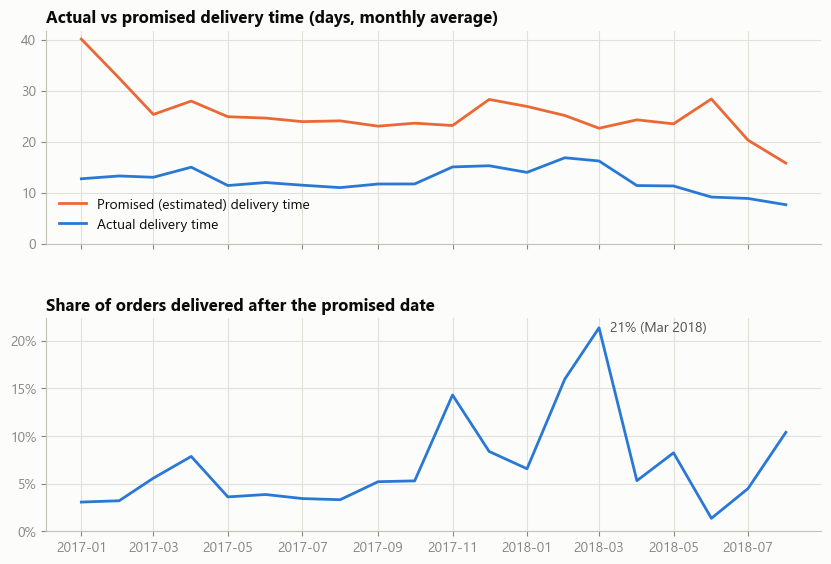

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"hspace": 0.35})
x = monthly["purchase_month"]

ax1.plot(x, monthly["avg_promised_days"], color=ORANGE, label="Promised (estimated) delivery time")
ax1.plot(x, monthly["avg_delivery_days"], color=BLUE, label="Actual delivery time")
ax1.set_title("Actual vs promised delivery time (days, monthly average)")
ax1.set_ylim(0, None)
ax1.legend(loc="lower left")

ax2.plot(x, monthly["late_rate"], color=BLUE)
ax2.set_title("Share of orders delivered after the promised date")
ax2.yaxis.set_major_formatter(pct)
ax2.set_ylim(0, None)
peak = monthly.loc[monthly["late_rate"].idxmax()]
ax2.annotate(f"{peak['late_rate']:.0%} ({peak['purchase_month']:%b %Y})",
             (peak["purchase_month"], peak["late_rate"]), xytext=(8, 0),
             textcoords="offset points", va="center", color=INK_2)

save(fig, "01_monthly_delivery_trend.png")
plt.show()

## 5. Q2 – Delivery performance by customer state

In [12]:
by_state = (
    delivered.groupBy("customer_state")
    .agg(
        F.count("*").alias("orders"),
        F.avg("delivery_days").alias("avg_delivery_days"),
        F.avg("is_late").alias("late_rate"),
    )
    .orderBy(F.desc("late_rate"))
    .toPandas()
)
by_state.round(3)

,customer_state,orders,avg_delivery_days,late_rate
0,AL,396,24.480,0.240
1,MA,713,21.474,0.196
2,PI,475,19.379,0.160
3,CE,1273,21.171,0.154
4,SE,332,21.380,0.154
5,BA,3253,19.277,0.140
6,RJ,12310,15.224,0.135
7,TO,274,17.599,0.128
8,RR,40,29.850,0.125
9,PA,942,23.709,0.124


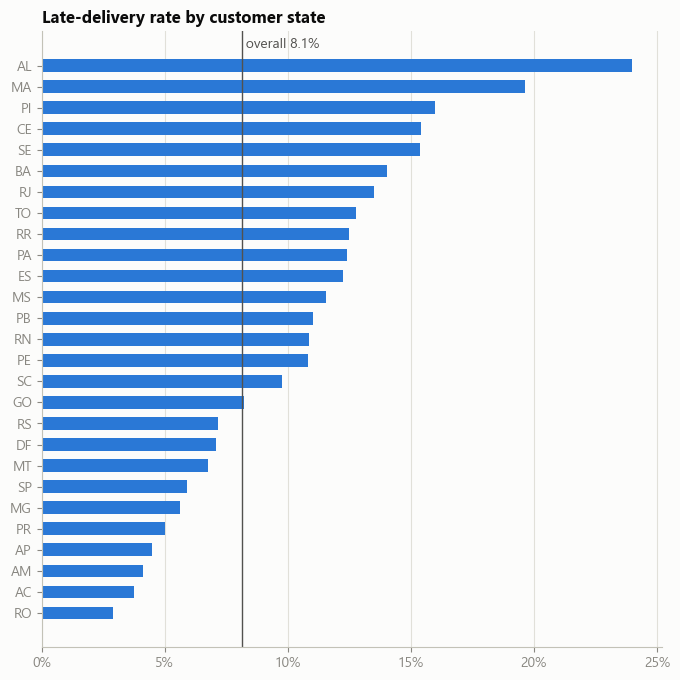

In [13]:
overall_late = delivered.agg(F.avg("is_late")).first()[0]
data = by_state.sort_values("late_rate")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(data["customer_state"], data["late_rate"], color=BLUE, height=0.6)
ax.axvline(overall_late, color=INK_2, linewidth=1)
ax.text(overall_late, len(data) - 0.3, f" overall {overall_late:.1%}", color=INK_2, va="bottom")
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.set_title("Late-delivery rate by customer state")
save(fig, "02_late_rate_by_state.png")
plt.show()

## 6. Q3 – Same-state vs cross-state deliveries

Only single-seller orders are used here (98% of orders), so each order has exactly one seller state.

In [14]:
route = (
    delivered.filter("n_sellers = 1")
    .withColumn("route", F.when(F.col("customer_state") == F.col("seller_state"), "Same state")
                          .otherwise("Different state"))
    .groupBy("route")
    .agg(
        F.count("*").alias("orders"),
        F.avg("delivery_days").alias("avg_delivery_days"),
        F.avg("is_late").alias("late_rate"),
        F.avg("freight_value").alias("avg_freight"),
    )
    .orderBy("route", ascending=False)
    .toPandas()
)
route.round(3)

,route,orders,avg_delivery_days,late_rate,avg_freight
0,Same state,34149,7.879,0.061,15.187
1,Different state,60782,15.131,0.094,26.555


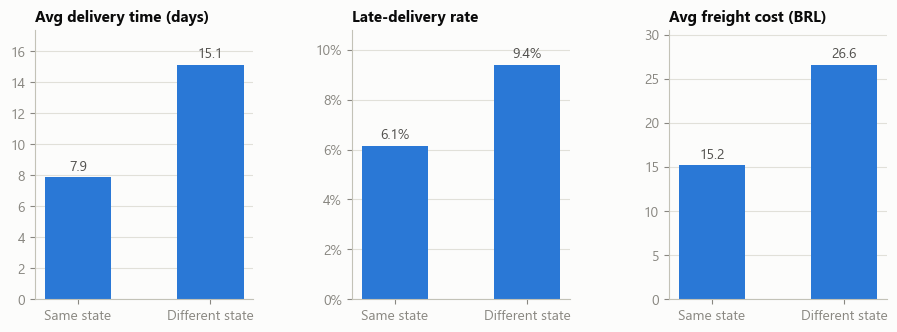

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), gridspec_kw={"wspace": 0.45})
panels = [("avg_delivery_days", "Avg delivery time (days)", "{:.1f}"),
          ("late_rate", "Late-delivery rate", "{:.1%}"),
          ("avg_freight", "Avg freight cost (BRL)", "{:.1f}")]
for ax, (col, title, fmt) in zip(axes, panels):
    bars = ax.bar(route["route"], route[col], color=BLUE, width=0.5)
    ax.bar_label(bars, labels=[fmt.format(v) for v in route[col]], padding=3, color=INK_2)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
    if col == "late_rate":
        ax.yaxis.set_major_formatter(pct)
save(fig, "03_same_vs_cross_state.png")
plt.show()

## 7. Q4 – Do late deliveries hurt review scores?

In [16]:
review_impact = (
    delivered.filter(F.col("review_score").isNotNull())
    .withColumn("delay",
        F.when(F.col("is_late") == 0, "On time")
         .when(F.col("days_late") <= 3, "1-3 days late")
         .when(F.col("days_late") <= 7, "4-7 days late")
         .when(F.col("days_late") <= 14, "8-14 days late")
         .otherwise("15+ days late"))
    .withColumn("sort_key",
        F.when(F.col("is_late") == 0, 0).when(F.col("days_late") <= 3, 1)
         .when(F.col("days_late") <= 7, 2).when(F.col("days_late") <= 14, 3).otherwise(4))
    .groupBy("sort_key", "delay")
    .agg(
        F.count("*").alias("orders"),
        F.avg("review_score").alias("avg_review_score"),
        F.avg((F.col("review_score") <= 2).cast("int")).alias("low_score_rate"),
    )
    .orderBy("sort_key")
    .toPandas()
    .drop(columns="sort_key")
)
review_impact.round(3)

,delay,orders,avg_review_score,low_score_rate
0,On time,87902,4.295,0.092
1,1-3 days late,3131,3.595,0.240
2,4-7 days late,1748,2.106,0.676
3,8-14 days late,1446,1.672,0.801
4,15+ days late,1333,1.727,0.782


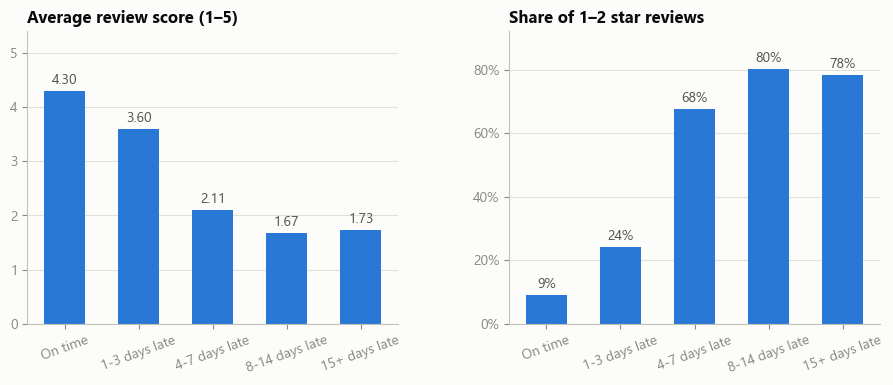

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.3})

bars = ax1.bar(review_impact["delay"], review_impact["avg_review_score"], color=BLUE, width=0.55)
ax1.bar_label(bars, labels=[f"{v:.2f}" for v in review_impact["avg_review_score"]], padding=3, color=INK_2)
ax1.set_title("Average review score (1–5)")
ax1.set_ylim(0, 5.4)

bars = ax2.bar(review_impact["delay"], review_impact["low_score_rate"], color=BLUE, width=0.55)
ax2.bar_label(bars, labels=[f"{v:.0%}" for v in review_impact["low_score_rate"]], padding=3, color=INK_2)
ax2.set_title("Share of 1–2 star reviews")
ax2.yaxis.set_major_formatter(pct)
ax2.margins(y=0.15)

for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelrotation=20)
save(fig, "04_delay_vs_review_score.png")
plt.show()

## 8. Q5 – Product categories

Item-level view: each order item is joined to its product category (translated to English).

In [18]:
by_category = (
    items.join(delivered.select("order_id", "is_late", "delivery_days"), "order_id")
    .join(products.select("product_id", "product_category_name"), "product_id", "left")
    .join(categories, "product_category_name", "left")
    .withColumn("category", F.coalesce("category", "product_category_name", F.lit("unknown")))
    .groupBy("category")
    .agg(
        F.count("*").alias("items"),
        F.sum("price").alias("revenue"),
        F.avg("is_late").alias("late_rate"),
        F.avg("delivery_days").alias("avg_delivery_days"),
        (F.sum("freight_value") / F.sum("price")).alias("freight_share"),
    )
    .orderBy(F.desc("revenue"))
    .toPandas()
)
top = by_category.head(15)
top.round(3)

,category,items,revenue,late_rate,avg_delivery_days,freight_share
0,health_beauty,9422,1229557.50,0.091,11.853,0.145
1,watches_gifts,5853,1163187.91,0.083,12.584,0.084
2,bed_bath_table,10945,1022955.77,0.084,12.748,0.197
3,sports_leisure,8413,952661.40,0.074,12.069,0.171
4,computers_accessories,7631,887944.60,0.078,13.143,0.162
5,furniture_decor,8095,706237.17,0.085,12.803,0.237
6,housewares,6783,614341.62,0.065,10.851,0.232
7,cool_stuff,3711,609158.00,0.068,12.301,0.133
8,auto,4131,577721.09,0.083,12.126,0.156
9,garden_tools,4263,469135.40,0.080,13.667,0.206


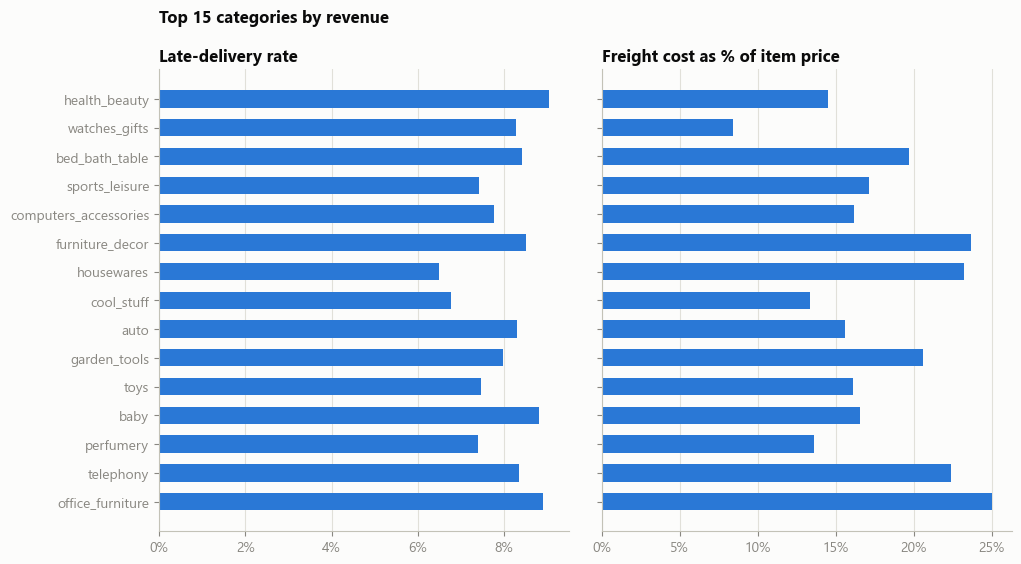

In [19]:
data = top.iloc[::-1]  # largest revenue at the top
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6), sharey=True, gridspec_kw={"wspace": 0.08})

ax1.barh(data["category"], data["late_rate"], color=BLUE, height=0.6)
ax1.set_title("Late-delivery rate")
ax1.xaxis.set_major_formatter(pct)

ax2.barh(data["category"], data["freight_share"], color=BLUE, height=0.6)
ax2.set_title("Freight cost as % of item price")
ax2.xaxis.set_major_formatter(pct)

for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 15 categories by revenue", x=0.125, ha="left", fontweight="bold", color=INK)
save(fig, "05_categories.png")
plt.show()

## 9. The same questions in Spark SQL

The DataFrame API and SQL compile to the same execution plan. Register the table as a view, then query it with SQL.

In [20]:
delivered.createOrReplaceTempView("delivered")

state_sql = spark.sql("""
    SELECT customer_state,
           COUNT(*)           AS orders,
           AVG(delivery_days) AS avg_delivery_days,
           AVG(is_late)       AS late_rate
    FROM delivered
    GROUP BY customer_state
    ORDER BY late_rate DESC
""").toPandas()

# Same result as the DataFrame API version in section 5
pd.testing.assert_frame_equal(
    state_sql.sort_values("customer_state").reset_index(drop=True),
    by_state.sort_values("customer_state").reset_index(drop=True),
)
print("SQL result matches the DataFrame API result")
state_sql.head(5).round(3)

SQL result matches the DataFrame API result


,customer_state,orders,avg_delivery_days,late_rate
0,AL,396,24.480,0.240
1,MA,713,21.474,0.196
2,PI,475,19.379,0.160
3,CE,1273,21.171,0.154
4,SE,332,21.380,0.154


In [21]:
spark.sql("""
    SELECT CASE WHEN is_late = 0 THEN 'On time' ELSE 'Late' END AS delivery,
           COUNT(*)                                             AS orders,
           ROUND(AVG(review_score), 2)                          AS avg_review_score,
           ROUND(AVG(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END), 3) AS low_score_rate
    FROM delivered
    WHERE review_score IS NOT NULL
    GROUP BY 1
    ORDER BY 1 DESC
""").toPandas()

,delivery,orders,avg_review_score,low_score_rate
0,On time,87902,4.30,0.092
1,Late,7658,2.57,0.540


## 10. Key findings

1. **Delays come from peak periods, not a steady decline.** The late rate stayed around 3–5% for most of 2017, then jumped to **14% in November 2017** (Black Friday) and **16–21% in February–March 2018**. In mid-2018 the promised delivery window was cut sharply (about 28 days in June to about 16 days in August). Actual deliveries got faster, but the late rate rose again to 10%. This explains why 2018 has both faster average deliveries and a higher late rate than 2017.
   *Caveat:* orders from August 2018 that were still in transit when the data was exported are not included, so the last months look faster than they really were.
2. **Geography is the biggest driver.** North-eastern states have 2–4× the late rate of São Paulo (AL 24%, MA 20%, CE and SE 15% vs SP 5.9%). **Rio de Janeiro** stands out: it is the second-largest market (12k orders) and has a 13.5% late rate. States with fewer than 100 orders (RR, AP, AC) are too small to draw conclusions from.
3. **Local orders are faster and cheaper.** When the seller and the customer are in the same state, delivery takes **7.9 days instead of 15.1**, the late rate is 6.1% instead of 9.4%, and freight costs 15.2 BRL instead of 26.6 BRL.
4. **Late deliveries hurt customer satisfaction.** On-time orders average **4.30 stars** (9% are 1–2 star reviews). Orders 4–7 days late average **2.11 stars** (68% are 1–2 star). The biggest drop happens between "1–3 days late" and "4–7 days late".
5. **Product category is not a major driver.** Late rates across the top 15 categories are similar (6.5–9.1%). Freight cost varies a lot more: it is 8% of the item price for watches and 25% for office furniture, which also takes the longest to deliver (20.7 days on average).

**Recommendations**

- Plan extra carrier capacity, or add buffer to the promised dates, before peak periods (Black Friday, February–March).
- Review carrier performance on the routes to Rio de Janeiro and the north-east. Consider a regional fulfilment point there.
- Recruit sellers outside São Paulo, or route orders to the nearest seller, to increase the share of same-state orders.
- Contact customers proactively when an order is expected to be more than 3 days late, since that is where review scores collapse.

In [22]:
spark.stop()